# 04. Chẩn đoán phần dư

Kiểm tra phần dư có hợp lý không.


In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
from cpi_forecast.models.naive import NaiveForecaster
from cpi_forecast.models.seasonal_naive import SeasonalNaiveForecaster
from cpi_forecast.models.moving_average import MovingAverageForecaster
from cpi_forecast.models.trend_ols import TrendOLSForecaster
from cpi_forecast.evaluation.diagnostics import (
    rolling_origin_errors, residual_summary, autocorrelation)

df = pd.read_csv("../data/processed/cpi_monthly_clean.csv", parse_dates=["date"])
models = {
    "Naive": NaiveForecaster,
    "Seasonal Naive": SeasonalNaiveForecaster,
    "Trung bình trượt (k=3)": lambda: MovingAverageForecaster(k=3),
    "Hồi quy xu hướng (OLS)": TrendOLSForecaster,
}


def summary_table(col):
    rows = []
    for name, factory in models.items():
        s = residual_summary(rolling_origin_errors(df[col].to_numpy(), factory, h=1))
        rows.append({"Mô hình": name,
                     "Trung bình sai số": round(s["trung_binh"], 3),
                     "Độ lệch chuẩn": round(s["do_lech_chuan"], 3),
                     "ACF lag 1": round(s["acf_lag1"], 2),
                     "ACF lag 12": round(s["acf_lag12"], 2)})
    return pd.DataFrame(rows)


print("CHUỖI CHỈ SỐ"); print(summary_table("index").to_string(index=False))
print("CHUỖI % THAY ĐỔI"); print(summary_table("pct").to_string(index=False))

CHUỖI CHỈ SỐ
               Mô hình  Trung bình sai số  Độ lệch chuẩn  ACF lag 1  ACF lag 12
                 Naive              0.857          1.269       0.46        0.09
        Seasonal Naive             10.465          6.973       0.97        0.24
Trung bình trượt (k=3)              1.729          2.001       0.75        0.08
Hồi quy xu hướng (OLS)            -11.724          9.511       0.98        0.68
CHUỖI % THAY ĐỔI
               Mô hình  Trung bình sai số  Độ lệch chuẩn  ACF lag 1  ACF lag 12
                 Naive             -0.009          0.515      -0.13        0.14
        Seasonal Naive             -0.033          0.734       0.56       -0.43
Trung bình trượt (k=3)             -0.015          0.548       0.31        0.13
Hồi quy xu hướng (OLS)              0.058          0.556       0.55        0.18


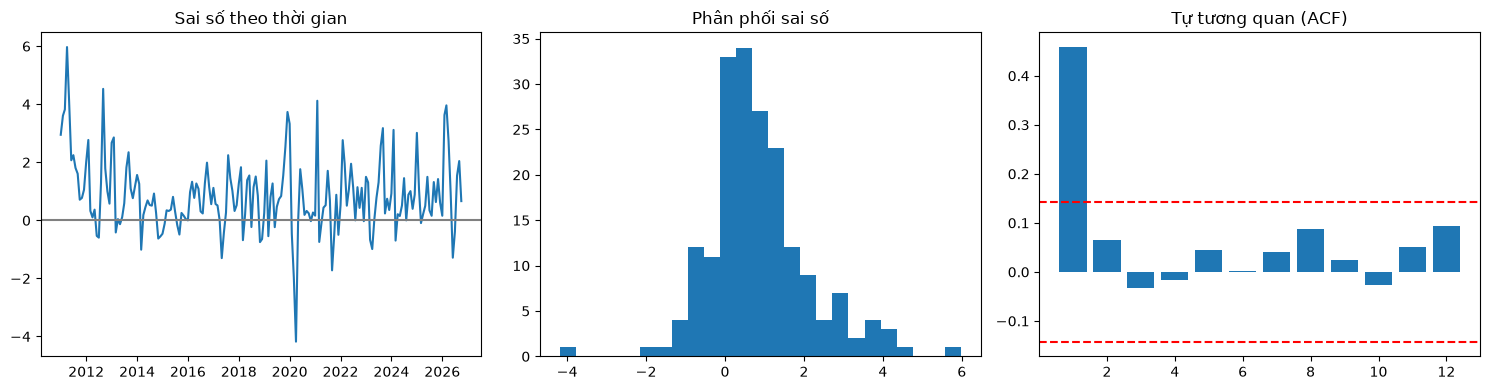

In [3]:
e = rolling_origin_errors(df["index"].to_numpy(), NaiveForecaster, h=1)
dates = df["date"].iloc[60:]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(dates, e); axes[0].axhline(0, color="gray"); axes[0].set_title("Sai số theo thời gian")
axes[1].hist(e, bins=25); axes[1].set_title("Phân phối sai số")
band = 1.96 / np.sqrt(len(e))
axes[2].bar(range(1, 13), autocorrelation(e, 12))
axes[2].axhline(band, ls="--", color="red"); axes[2].axhline(-band, ls="--", color="red")
axes[2].set_title("Tự tương quan (ACF)")
plt.tight_layout(); plt.show()